# Finite volume method:

## Top-hat function advection

We solve the linear advection equation in conservation form,

$$\frac{\partial u}{\partial t} + \frac{\partial F(u)}{\partial x} = 0$$

with:

$$F(u) = c\,u$$

on a finite-volume (FV) grid, and we compare two reconstructions inside each cell:

| method | slope |
|---|---|
| `godunov` | no slope (piecewise-constant) |
| `unlimited` | centred difference method|


**Reference**: M. Zingale, *Introduction to Computational Astrophysical Hydrodynamics*,

Notation follows the lectures: $u$ is the advected state, $c$ the advection speed and $C = c\,\Delta t / \Delta x$ the Courant number.

In [15]:
import numpy as np
import matplotlib.pyplot as plt

### 1. Define our domain (spatial discretisation):

In [16]:
# Domain limits:
xmin = 0.
xmax = 1.

# Number of cells
nx = 512

# Number of ghost cells on each side
ng = 2

# Lowest and highest indices
ilo = ng
ihi = ng + nx - 1

print("First cell index: ", ilo)
print("Last cell index: ", ihi)


First cell index:  2
Last cell index:  513


In [17]:
# Step size
dx = (xmax - xmin)/(nx)

# X axis vector -> we need the cell centres:
x = xmin + (np.arange(nx + 2*ng) - ng + 0.5)*dx

#print(x.shape)

### 2. Create vector to store solution array:

#### Include initial conditions: top-hat function in the middle

In [18]:
# Empty vector for the solution in double precision:
u = np.zeros((nx + 2*ng), dtype = np.float64)

# Add initial conditions
u[:] = 0.
u[np.logical_and(x >= 1./3., x <= 2./3.)] = 1. # Top-hat function

# Make a copy of the initial condition:
uinit = u.copy()

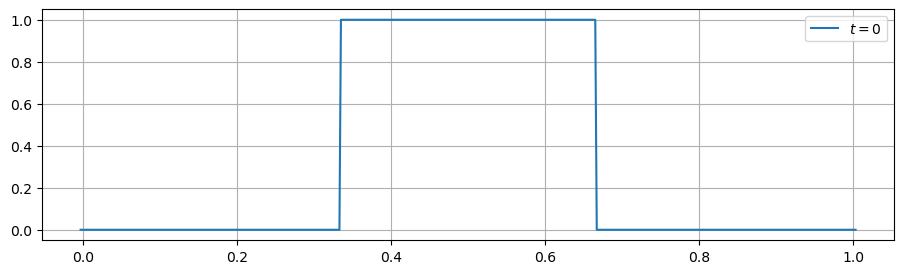

In [19]:
# Plotting the initial condition

plt.figure(figsize=(11,3))
plt.plot(x, u, label = r"$t=0$")
plt.grid()
plt.legend()
plt.show()

### 3. Time discretisation:

In [20]:
# Define perturbation velocity
c = 1.

# Define Courant number
cfl = 0.7

# Define number of periods
num_periods = 5.

# Calculate period 
period = (xmax - xmin)/c

# Maximmum simulation time
tmax = num_periods*period

### 4. Evolution Loop

- Define functions for implementing the finite volume method.

- While statement for the time update.


In [21]:
# Functions that will be called by the while statement

def states(dx, dt):
    
    # Empty vector for the slope delta u /delta x = ?
    slope = np.zeros((nx + 2*ng), dtype = np.float64)
    
    # This could be into a function
    
    # 1st approach: Godunov approach
    slope[:] = 0. 
    
    # 2nd approach: Centred difference method
    #for i in range(ilo - 1, ihi + 2):
    #    slope[i] = 0.5*(u[i + 1] - u[i-1])/dx
    
    # Empty vector for the L and R states
    ul = np.zeros((nx + 2*ng), dtype = np.float64)
    ur = np.zeros((nx + 2*ng), dtype = np.float64)
    
    # Add derivative calculation
    for i in range(ilo, ihi + 2):
        
        # Compute L state
        ul[i] = u[i - 1] + 0.5*dx*(1. - c*dt/dx)*slope[i-1]
        
        # Compute R state
        ur[i] = u[i] - 0.5*dx*(1. + c*dt/dx)*slope[i]
        
    return ul, ur
  
def riemann(ul, ur):
    # Computing the flux
    if c > 0.:
        return c*ul
    else: 
        return c*ur
    
def conservative_update(dt, flux):
    
    # Empty vector for updated solution
    unew = np.zeros((nx + 2*ng), dtype = np.float64)
    
    # Update
    unew[ilo:ihi+1] = u[ilo:ihi+1] - dt/dx*(flux[ilo+1:ihi+2] - flux[ilo:ihi+1])
    
    # Return
    return unew

- While statement for the time update.

In [22]:
# While statement
# Initialise
t = 0.

# We start while:
while t < tmax:
    
    # Fill up the boundary conditions BCs
    for n in range(ng):
        # The left BC is
        u[ilo - 1 - n] = u[ihi - n]
        # The right BC is
        u[ihi + 1 + n] = u[ilo + n]
    
    # Get time step
    dt = cfl*dx/c
    
    if t + dt > tmax:
        dt = tmax - t
    
    # Get interface states
    ul, ur = states(dx, dt)
    
    # Solve Riemann problem
    flux = riemann(ul, ur)
    
    # Do the conservative update
    unew = conservative_update(dt, flux)
    
    # Retrieve solution
    u[:] = unew[:]
    
    # Advance in time
    t += dt

### Case 1: Piecewise constant, $0$ slopes:

### 5. Inspect solution:

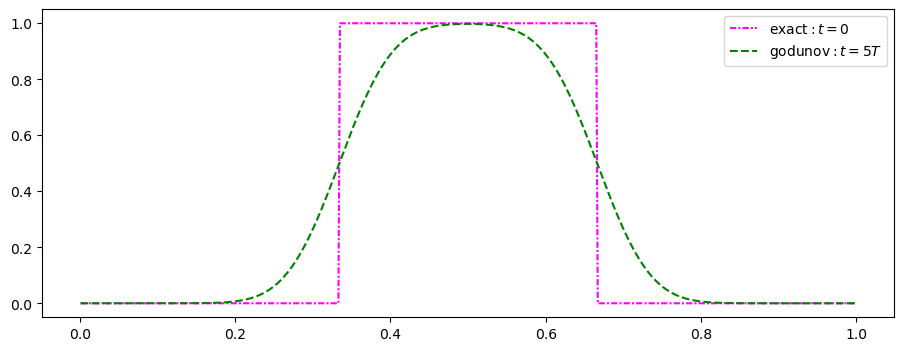

In [23]:
# Plotting the initial condition

plt.figure(figsize=(11,4))

plt.plot(x[ilo:ihi+1], uinit[ilo:ihi+1], color = "magenta", linestyle = (0, (3, 1, 1, 1)), label = r"${\rm exact}: t=0$")
plt.plot(x[ilo:ihi+1], u[ilo:ihi+1], color = "green", linestyle = "--", label = r"${\rm godunov}: t=5 T$")
plt.legend()
plt.show()

In [24]:
# Make copy of first sln
u_sln1 = u.copy()

### Case 2: Centred-difference slope:

In [25]:
# Empty vector for the solution in double precision:
u = np.zeros((nx + 2*ng), dtype = np.float64)

# Add initial conditions;
u[:] = 0.
u[np.logical_and(x >= 1./3., x <= 2./3.)] = 1. # Top-hat function

# Make a copy of the initial condition:
uinit = u.copy()

In [26]:
# Functions that will be called by the while statement

def states(dx, dt):
    
    # Empty vector for the slope
    slope = np.zeros((nx + 2*ng), dtype = np.float64)
    
    # This could be into a function
    
    # 1st approach: Godunov approach
    #slope[:] = 0. 
    
    # 2nd approach: Centred difference method
    for i in range(ilo - 1, ihi + 2):
        slope[i] = 0.5*(u[i + 1] - u[i - 1])/dx
    
    # Empty vector dor the L and R states
    ul = np.zeros((nx + 2*ng), dtype = np.float64)
    ur = np.zeros((nx + 2*ng), dtype = np.float64)
    
    # Add derivative calculation
    for i in range(ilo, ihi + 2):
        
        # Compute L state
        ul[i] = u[i - 1] + 0.5*dx*(1. - c*dt/dx)*slope[i-1]
        
        # Compute R state
        ur[i] = u[i] - 0.5*dx*(1. + c*dt/dx)*slope[i]
        
    return ul, ur
  
def riemann(ul, ur):
    # Computing the flux
    if c > 0.:
        return c*ul
    else: 
        return c*ur
    
def conservative_update(dt, flux):
    
    # Empty vector for updated solution
    unew = np.zeros((nx + 2*ng), dtype = np.float64)
    
    # Update
    unew[ilo:ihi+1] = u[ilo:ihi+1] -\
    dt/dx*(flux[ilo+1:ihi+2] - flux[ilo:ihi+1])
    
    # Return
    return unew

In [27]:
# While statement
# Initialise
t = 0.

# We start while:
while t < tmax:
    
    # Fill up the boundary conditions BCs
    for n in range(ng):
        # The left BC is
        u[ilo - 1 - n] = u[ihi - n]
        # The right BC is
        u[ihi + 1 + n] = u[ilo + n]
    
    # Get time step
    dt = cfl*dx/c
    
    if t + dt > tmax:
        dt = tmax - t
    
    # Get interface states
    ul, ur = states(dx, dt)
    
    # Solve Riemann problem
    flux = riemann(ul, ur)
    
    # Do the conservative update
    unew = conservative_update(dt, flux)
    
    # Retrieve solution
    u[:] = unew[:]
    
    # Advance in time
    t += dt

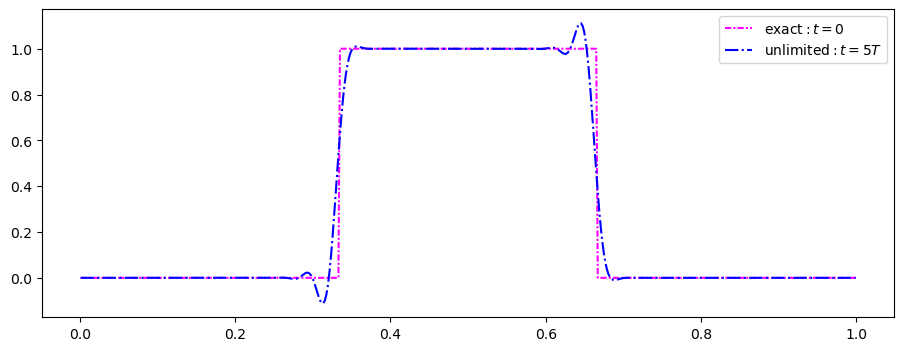

In [28]:
# Plotting the initial condition

plt.figure(figsize=(11,4))

plt.plot(x[ilo:ihi+1], uinit[ilo:ihi+1], color = "magenta", linestyle = (0, (3, 1, 1, 1)), label = r"${\rm exact}: t=0$")
plt.plot(x[ilo:ihi+1], u[ilo:ihi+1], color = "blue", linestyle = "-.", label = r"${\rm unlimited}: t=5 T$")
plt.legend()
plt.show()

### Comparison:

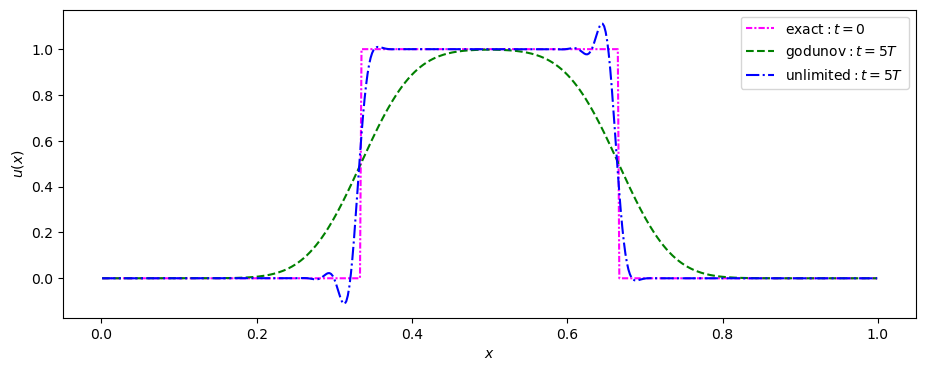

In [30]:
# Plotting the initial condition

plt.figure(figsize=(11,4))

plt.plot(x[ilo:ihi+1], uinit[ilo:ihi+1], color = "magenta", linestyle = (0, (3, 1, 1, 1)), label = r"${\rm exact}: t=0$")

plt.plot(x[ilo:ihi+1], u_sln1[ilo:ihi+1], color = "green", linestyle = "--", label = r"${\rm godunov}: t=5 T$")

plt.plot(x[ilo:ihi+1], u[ilo:ihi+1], color = "blue", linestyle = "-.", label = r"${\rm unlimited}: t=5 T$")
plt.legend()
plt.xlabel(r"$x$")
plt.ylabel(r"$u(x)$")
plt.show()

## Slope Limiting

Godunov's theorem says that any monotonic *linear* method for advection is only
first-order accurate. So a second-order method that does not oscillate has to be
**nonlinear**: the slope itself has to depend on the data. Every method below
differs in one line only, the slope in cell $i$.

**1. Godunov**, piecewise-constant data, no reconstruction:

$$\left.\frac{\partial u}{\partial x}\right|_i = 0$$

**2. Unlimited**, the centred difference:

$$\left.\frac{\partial u}{\partial x}\right|_i
= \frac{u_{i+1} - u_{i-1}}{2\,\Delta x}$$

Second-order on smooth data, and it overshoots at a discontinuity.

**3. Minmod limiter**, the two one-sided differences, whichever is smaller:

$$\left.\frac{\partial u}{\partial x}\right|_i
= {\rm minmod}\left(\frac{u_i - u_{i-1}}{\Delta x},\;
\frac{u_{i+1} - u_i}{\Delta x}\right),
\qquad
{\rm minmod}(a,b) =
\begin{cases}
a & |a| \le |b| \;\text{and}\; a\,b > 0 \\
b & |b| \le |a| \;\text{and}\; a\,b > 0 \\
0 & a\,b \le 0
\end{cases}$$

The test on the product $a\,b$ is the whole idea. It is negative at an extremum,
which is exactly where the slope has to be cut to zero.

**4. MC limiter**, the monotonised central difference:

$$\left.\frac{\partial u}{\partial x}\right|_i
= {\rm minmod}\left[\,
{\rm minmod}\left(\frac{2(u_i - u_{i-1})}{\Delta x},\;
\frac{2(u_{i+1} - u_i)}{\Delta x}\right),\;
\frac{u_{i+1} - u_{i-1}}{2\,\Delta x}\,\right]$$

It keeps the centred slope wherever that slope is no steeper than twice either
one-sided difference, so it holds on to more of the second-order accuracy than
minmod does, and it still goes to zero at an extremum.

The four runs below start from the same top hat and share the same time steps,
so the only difference between them is the slope.

### Slope limiter MINMOD

In [31]:
# Functions for flux limiters

# MinMod Function

def minmod(a, b):

    if abs(a) <= abs(b) and a*b > 0.0:
        return a

    if abs(b) <= abs(a) and a*b > 0.0:
        return b

    else:
        return 0.0

### Four solution vectors, one per slope:

In [32]:
# Empty vectors for the four solutions, in double precision:
u1 = np.zeros((nx + 2*ng), dtype = np.float64)   # godunov
u2 = np.zeros((nx + 2*ng), dtype = np.float64)   # unlimited
u3 = np.zeros((nx + 2*ng), dtype = np.float64)   # minmod
u4 = np.zeros((nx + 2*ng), dtype = np.float64)   # mc

# Add initial conditions: the same top-hat function for all four
for uk in (u1, u2, u3, u4):
    uk[:] = 0.
    uk[np.logical_and(x >= 1./3., x <= 2./3.)] = 1.

# Make a copy of the initial condition:
u0 = u1.copy()

### Evolution loop, with the slope chosen by name:

In [33]:
# Functions that will be called by the while statement

def fill_bcs(u):
    # Fill up the boundary conditions BCs
    for n in range(ng):
        # The left BC is
        u[ilo - 1 - n] = u[ihi - n]
        # The right BC is
        u[ihi + 1 + n] = u[ilo + n]
    return u

def states(u, dx, dt, method):

    # Empty vector for the slope
    slope = np.zeros((nx + 2*ng), dtype = np.float64)

    # This could be into a function

    if method == "godunov":
        # 1st approach: Godunov approach
        slope[:] = 0.
    elif method == "unlimited":
        # 2nd approach: Centred difference method
        for i in range(ilo - 1, ihi + 2):
            slope[i] = 0.5*(u[i + 1] - u[i-1])/dx
    elif method == "minmod":
        # 3rd approach: minmod limiter
        for i in range(ilo - 1, ihi + 2):
            slope[i] = minmod((u[i] - u[i-1])/dx, (u[i+1] - u[i])/dx)
    elif method == "mc":
        # 4th approach: MC limiter
        for i in range(ilo - 1, ihi + 2):
            slope[i] = minmod(minmod(2*(u[i] - u[i-1])/dx, 2*(u[i+1]\
                       - u[i])/dx), 0.5*(u[i+1] - u[i-1])/dx)

    # Empty vector for the L and R states
    ul = np.zeros((nx + 2*ng), dtype = np.float64)
    ur = np.zeros((nx + 2*ng), dtype = np.float64)

    # Add derivative calculation
    for i in range(ilo, ihi + 2):

        # Compute L state
        ul[i] = u[i - 1] + 0.5*dx*(1. - c*dt/dx)*slope[i-1]

        # Compute R state
        ur[i] = u[i] - 0.5*dx*(1. + c*dt/dx)*slope[i]

    return ul, ur

def riemann(ul, ur):
    # Computing the flux
    if c > 0.:
        return c*ul
    else:
        return c*ur

def conservative_update(u, dt, flux):

    # Empty vector for updated solution
    unew = np.zeros((nx + 2*ng), dtype = np.float64)

    # Update
    unew[ilo:ihi+1] = u[ilo:ihi+1] - dt/dx*(flux[ilo+1:ihi+2] - flux[ilo:ihi+1])

    # Return
    return unew

In [34]:
# While statement
# Initialise
t = 0.

# We start while:
while t < tmax:

    u1 = fill_bcs(u1)
    u2 = fill_bcs(u2)
    u3 = fill_bcs(u3)
    u4 = fill_bcs(u4)

    # Get time step
    dt = cfl*dx/c

    if t + dt > tmax:
        dt = tmax - t

    # Get interface states
    ul1, ur1 = states(u1, dx, dt, "godunov")
    ul2, ur2 = states(u2, dx, dt, "unlimited")
    ul3, ur3 = states(u3, dx, dt, "minmod")
    ul4, ur4 = states(u4, dx, dt, "mc")

    # Solve Riemann problem
    flux1 = riemann(ul1, ur1)
    flux2 = riemann(ul2, ur2)
    flux3 = riemann(ul3, ur3)
    flux4 = riemann(ul4, ur4)

    # Do the conservative update
    unew1 = conservative_update(u1, dt, flux1)
    unew2 = conservative_update(u2, dt, flux2)
    unew3 = conservative_update(u3, dt, flux3)
    unew4 = conservative_update(u4, dt, flux4)

    # Retrieve solution
    u1[:] = unew1[:]
    u2[:] = unew2[:]
    u3[:] = unew3[:]
    u4[:] = unew4[:]

    # Advance in time
    t += dt

### Inspect the four solutions:

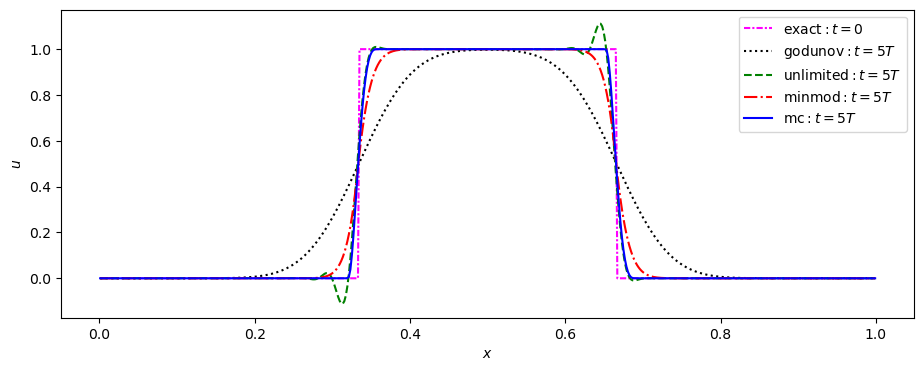

In [35]:
# Plotting the four solutions against the initial condition

plt.figure(figsize=(11,4))

plt.plot(x[ilo:ihi+1], u0[ilo:ihi+1], color = "magenta", linestyle = (0, (3, 1, 1, 1)), label = r"${\rm exact}: t=0$")
plt.plot(x[ilo:ihi+1], u1[ilo:ihi+1], color = "black", linestyle = ":", label = r"${\rm godunov}: t=5 T$")
plt.plot(x[ilo:ihi+1], u2[ilo:ihi+1], color = "green", linestyle = "--", label = r"${\rm unlimited}: t=5 T$")
plt.plot(x[ilo:ihi+1], u3[ilo:ihi+1], color = "red", linestyle = "-.", label = r"${\rm minmod}: t=5 T$")
plt.plot(x[ilo:ihi+1], u4[ilo:ihi+1], color = "blue", linestyle = "-", label = r"${\rm mc}: t=5 T$")

plt.xlabel(r"$x$")
plt.ylabel(r"$u$")
plt.legend()
plt.show()

### Overshoots and undershoots:

In [38]:
# Overshoots and undershoots, zone by zone

for name, uk in [("godunov", u1), ("unlimited", u2), ("minmod", u3), ("mc", u4)]:
    print("%-10s min = %8.5f   max = %8.5f" % (name, uk[ilo:ihi+1].min(), uk[ilo:ihi+1].max()))

godunov    min =  0.00000   max =  0.99784
unlimited  min = -0.11104   max =  1.11104
minmod     min =  0.00000   max =  1.00000
mc         min =  0.00000   max =  1.00000


### Other flux limiters:

https://en.wikipedia.org/wiki/Flux_limiter